## CESM-LE SWE Nonstationary GP Modeling

This notebook tests a nonstationary Gaussian process model based on the CESM-LE SWE k-means clustering analysis.  

### Import Libraries

Import necessary libraries

In [1]:
import numpy
import numpy.ma as ma
from netCDF4 import Dataset
import quantile_supp
import pandas
from numpy import random
import datetime
import sys

from numpy import linalg

### Read Ensemble Info

Experiment metadata is stored in the CSV file `LENS_BTM_Cases_PrdBlk.csv`

In [2]:
rffl = 'LENS_BTM_Cases_PrdBlk.csv'
csfrm = pandas.read_csv(rffl, dtype = {'DateFmt8':int, 'RCP':str, 'LocName':str})
rwidx = 2

tgtdt = csfrm['DateFmt8'].values[rwidx]
rcptxt = csfrm['RCP'].values[rwidx]
stntxt = csfrm['LocName'].values[rwidx]
if rcptxt == 'Yes':
    rcpscn = True
else:
    rcpscn = False

case_str = 'GP scoring for %d, RCP: %s\n Prediction location %s' % (tgtdt,rcptxt,stntxt)
print(case_str)

GP scoring for 20050413, RCP: No
 Prediction location C


Ensemble data and cluster membership are stored in NetCDF files.

In [3]:
### Ensemble preparation
# Read Quantiles, mask, locations, clusters
qfnm = 'LENS_NAmer_H2OSNO_%d_Quantile.nc' % (tgtdt)
ncclm = Dataset(qfnm,'r')
utmx = ncclm.variables['UTM_easting'][:,:]
utmy = ncclm.variables['UTM_northing'][:,:]
snomsk = ncclm.variables['LENS_mask'][:,:]
ltidx = ncclm.variables['lat_index'][:]
lnidx = ncclm.variables['lon_index'][:]
lat = ncclm.variables['latitude'][:]
lon = ncclm.variables['longitude'][:]
h2oqs = ncclm.variables['H2OSNO_quantile'][:,:,:]
prbs = ncclm.variables['probability'][:]
clstid = ncclm.variables['cluster'][:,:]
snofl = ncclm.variables['H2OSNO_ensemble'][:,:,:]
# Read prediction blocks 
prdmsk = ncclm.variables['predict_mask'][:,:]
ncclm.close()

nmbr = snofl.shape[0]
print(nmbr)

# Read ensemble members, re-structure
nlat = ltidx.shape[0]
nlon = lnidx.shape[0]
lndv = (lon[1] - lon[0]) / 2.0
ltdv = (lat[1] - lat[0]) / 2.0

ltrp = numpy.repeat(lat,nlon)
lnrp = numpy.tile(lon,nlat)
lnarr = numpy.reshape(lnrp,(nlat,nlon))
ltarr = numpy.reshape(ltrp,(nlat,nlon))

# Loop through and transform
mskchk = snomsk[snomsk == 1]
nvld = mskchk.shape[0]
print(mskchk.shape)
print(snomsk.shape)

42
(1690,)
(71, 90)


Next, process ensemble into normal scores and set up spatial location info

In [4]:
zout = numpy.zeros((nmbr,nvld), dtype=numpy.float32)
yout = numpy.zeros((nmbr,nvld), dtype=numpy.float32)
lcsout = numpy.zeros((nvld,2), dtype=numpy.float32)
xidx = numpy.zeros((nvld,), dtype=numpy.int16)
yidx = numpy.zeros((nvld,), dtype=numpy.int16)
clstvc = numpy.zeros((nvld,), dtype=numpy.int16)
prdmvc = numpy.zeros((nvld,), dtype=numpy.int16)
lcctr = 0
for q in range(nlat):
    for p in range(nlon):
        if snomsk[q,p] == 1:
            ztmp = quantile_supp.std_norm_quantile_from_obs(snofl[:,q,p], h2oqs[q,p,:], prbs, msgval=-9999.)
            zout[:,lcctr] = ztmp[:]
            yout[:,lcctr] = snofl[:,q,p]
            lcsout[lcctr,0] = utmx[q,p]
            lcsout[lcctr,1] = utmy[q,p]
            clstvc[lcctr] = clstid[q,p]
            prdmvc[lcctr] = prdmsk[q,p]
            xidx[lcctr] = p
            yidx[lcctr] = q
            lcctr = lcctr + 1
nclst = int(numpy.amax(clstvc)) + 1

# Scale locations
lcsadj = numpy.zeros(lcsout.shape,dtype=lcsout.dtype)
lcsadj[:,0] = (lcsout[:,0] + 150.0) / 6500.0
lcsadj[:,1] = (lcsout[:,1] - 6750.0) / 6500.0

### Find Cluster Centroids

Next, loop through each cluster and find a central location to be used for the nonstationary model.

In [5]:
lsq = numpy.arange(nvld)

xictr = numpy.zeros( (nclst,), dtype=numpy.int32)
yictr = numpy.zeros( (nclst,), dtype=numpy.int32)
iictr = numpy.zeros( (nclst,), dtype=numpy.int32)

for q in range(nclst):
    strst = 'Optimizing Cluster %d' % (q+1)
    print(strst)

    lcr = lsq[clstvc == q]
    xcr = lcsadj[lcr,:]
    zchk = zout[0,lcr]

    # Distance matrix for cluster
    nlcclst = lcr.shape[0]
    urps = numpy.tile(xcr[:,0], (nlcclst,1))
    vrps = numpy.tile(xcr[:,1], (nlcclst,1))

    udif = urps - numpy.transpose(urps)
    vdif = vrps - numpy.transpose(vrps)
    dstmt = numpy.sqrt( (udif * udif) + (vdif * vdif) )

    dstmd = numpy.median(dstmt,axis=0)

    dstminmd = numpy.amin(dstmd)
    lcmin = lcr[dstmd == dstminmd]
    print(lcmin.shape)
    xictr[q] = xidx[lcmin[0]]
    yictr[q] = yidx[lcmin[0]]
    iictr[q] = lcmin[0]
    
    strclst = 'Cluster %d Distances. Smallest Median: %.4f,  Median Median: %.4f' % (q+1,numpy.amin(dstmd),numpy.median(dstmd))
    print(strclst)

print(xictr)
print(yictr)
print(iictr)

Optimizing Cluster 1
(1,)
Cluster 1 Distances. Smallest Median: 0.1158,  Median Median: 0.1533
Optimizing Cluster 2
(1,)
Cluster 2 Distances. Smallest Median: 0.1541,  Median Median: 0.2488
Optimizing Cluster 3
(1,)
Cluster 3 Distances. Smallest Median: 0.1070,  Median Median: 0.1395
Optimizing Cluster 4
(1,)
Cluster 4 Distances. Smallest Median: 0.0729,  Median Median: 0.1190
Optimizing Cluster 5
(1,)
Cluster 5 Distances. Smallest Median: 0.1026,  Median Median: 0.1394
Optimizing Cluster 6
(1,)
Cluster 6 Distances. Smallest Median: 0.0519,  Median Median: 0.0700
[77 43 43  9 28 55]
[38 31 42 53 51 51]
[ 525  167  712 1308 1188 1215]


### Map Clusters and Centroids

Plot cluster membership and centroids on a map

In [6]:
import matplotlib
from matplotlib import pyplot, colors
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

import cartopy.crs as ccrs
import cartopy.feature as cfeature



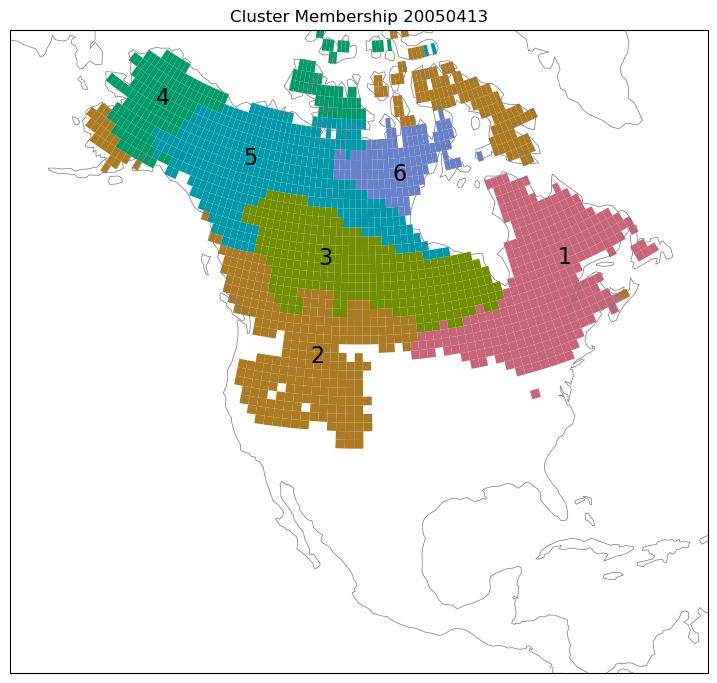

In [7]:
%matplotlib inline

c6 = ["#C7657B","#AC7A23","#718E00","#009A68","#0098A9","#6881C9"]
# Map clusters
asq = numpy.arange(nvld)
fig = pyplot.figure(figsize=(9,9))
trnsfrm = ccrs.PlateCarree()
pmp = fig.add_subplot(1,1,1, projection=ccrs.LambertConformal(central_longitude=-105, central_latitude=33) )
for q in range(nclst):
    lcr = lsq[clstvc == q]
    nct = lcr.shape[0]
    patches = []
    for j in range(nct):
        ltcr = lat[yidx[lcr[j]]]
        lncr = lon[xidx[lcr[j]]]
        rectmn = numpy.array([[lncr-lndv,ltcr-ltdv],[lncr-lndv,ltcr+ltdv],[lncr+lndv,ltcr+ltdv],[lncr+lndv,ltcr-ltdv]])
        patches.append(Polygon(rectmn))
    pmp.add_collection(PatchCollection(patches, facecolor=c6[q], edgecolor='#444444', linewidth=0, transform=trnsfrm))

    # Add centroid
    pltstr = '%d' % (q+1)
    pyplot.text(lon[xictr[q]], lat[yictr[q]], pltstr, \
                fontsize=16, color='#000000', verticalalignment='center', transform=trnsfrm)

pmp.coastlines(color='#777777',linewidth=0.5)
pmp.set_extent([-140, -70, 10, 75])
tstr = 'Cluster Membership %d' % (tgtdt) 
pttl = pyplot.title(tstr)

pyplot.show()

### Fit GP Models

Fit local GP models by cluster/location. Subset to locations in the cluster of interest **and** within specified distance of cluster centroid. Also subset to first 24 ensemble members for fitting.

In [8]:
import torch
import gpytorch
from torch.distributions import MultivariateNormal
import math

torch.set_num_threads(1)
torch.set_num_interop_threads(1)

Compute distances to each cluster centroid

In [9]:
dstarr = numpy.zeros( (nclst,nvld), dtype=numpy.float32)
mdst = 0.5

for q in range(nclst):

    # Distance array to cluster center
    udif = lcsadj[:,0] - lcsadj[iictr[q],0]
    vdif = lcsadj[:,1] - lcsadj[iictr[q],1]
    dstarr[q,:] = numpy.sqrt( (udif*udif + vdif * vdif) )
    
    lcr = lsq[clstvc == q]
    lcr2 = lsq[ (clstvc == q) & (dstarr[q,:] <= mdst) ]

    strcl = 'Cluster %d:  %d members, %d within %.2f' % (q+1, lcr.shape[0], lcr2.shape[0], mdst)
    print(strcl)
    
    #xcr = lcsadj[lcr,:]
    #zchk = zout[0,lcr]

    #nlcclst = lcr.shape[0]
    #urps = numpy.tile(xcr[:,0], (nlcclst,1))
    #vrps = numpy.tile(xcr[:,1], (nlcclst,1))



Cluster 1:  311 members, 311 within 0.50
Cluster 2:  405 members, 296 within 0.50
Cluster 3:  296 members, 296 within 0.50
Cluster 4:  194 members, 194 within 0.50
Cluster 5:  368 members, 368 within 0.50
Cluster 6:  116 members, 116 within 0.50


Likelihood estimates are found for each clsuter

In [10]:
zout.shape

(42, 1690)

In [11]:
nenstrn = 24
optchc = "LBGFS"
ztrn = zout[0:nenstrn,:]
mtrnnu = 1.5

class ExactGPModel(gpytorch.models.ExactGP):
    def __init__(self, xlcs, zdat, likelihood, smooth=0.5):
        super(ExactGPModel, self).__init__(xlcs, zdat, likelihood)
        self.mean_module = gpytorch.means.ZeroMean()
        self.covar_module = gpytorch.kernels.ScaleKernel(gpytorch.kernels.MaternKernel(nu=smooth))
    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

#zchk = torch.from_numpy(ztrn[0,lcr]).float()
#likelihood = gpytorch.likelihoods.GaussianLikelihood()
#model = ExactGPModel(index_pts, zchk, likelihood, smooth=0.5)

for q in range(nclst):
    strst = 'Optimizing Cluster %d' % (q+1)
    print(strst)

    lcr = lsq[ (clstvc == q) & (dstarr[q,:] <= mdst) ]
    print(lcr.shape)
    xcr = torch.tensor(lcsadj[lcr,:])
    zchk = torch.from_numpy(ztrn[0,lcr]).float()

    likelihood = gpytorch.likelihoods.GaussianLikelihood()
    model = ExactGPModel(xcr, zchk, likelihood, smooth=mtrnnu)
    #model = ExactGPModel(xcr, zchk, likelihood)

    model.covar_module.base_kernel.lengthscale = torch.tensor(0.2)
    model.likelihood.noise = torch.tensor(0.1)

    # Find optimal model hyperparameters
    model.train()
    likelihood.train()
    
    # "Loss" for GPs - the marginal log likelihood
    mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)


    training_iter = 10
    optimizer = torch.optim.LBFGS(model.parameters(), history_size=20, max_iter=training_iter, \
                                    line_search_fn='strong_wolfe')

    # Define the closure function
    def closure():
        optimizer.zero_grad()
        output = model(xcr)
        loss = 0
        for t in range(nenstrn):
            zchk = torch.from_numpy(ztrn[t,lcr]).float()
            loss = loss-mll(output, zchk)
        loss.backward()
        return loss

    # Optimization loop
    for i in range(training_iter):
        optimizer.step(closure)
        loss = closure()
        #if ( (i % 2) == 1):
        print('Iter %d/%d - Loss: %.5f   lengthscale: %.4f   gpvar: %.4f   noise: %.4f' % (
            i + 1, training_iter, loss.item(),
            model.covar_module.base_kernel.lengthscale.item(),
            model.covar_module.outputscale.item(),
            model.likelihood.noise.item()
        ))

    covarfn = model.covar_module(xcr) 
 
    # Output to frame
    lkfrm = pandas.DataFrame({'Cluster': q+1, 'Locations': covarfn.shape[0], 'Loss': loss.item(), 'Lengthscale': model.covar_module.base_kernel.lengthscale.item(), \
                              'VarScale': model.covar_module.outputscale.item(), 'Nugget': model.likelihood.noise.item()}, index=[q])
    if q == 0:
        prlstout = lkfrm
    else:
        prlstout = pandas.concat([prlstout, lkfrm], ignore_index=True)



Optimizing Cluster 1
(311,)


Iter 1/10 - Loss: 19.12319   lengthscale: 0.0489   gpvar: 1.1817   noise: 0.1149


Iter 2/10 - Loss: 19.12314   lengthscale: 0.0492   gpvar: 1.1887   noise: 0.1153


Iter 3/10 - Loss: 19.12314   lengthscale: 0.0492   gpvar: 1.1887   noise: 0.1153


Iter 4/10 - Loss: 19.12314   lengthscale: 0.0492   gpvar: 1.1887   noise: 0.1153


Iter 5/10 - Loss: 19.12314   lengthscale: 0.0492   gpvar: 1.1887   noise: 0.1153


... (51 outputs left out)

Iter 7/10 - Loss: 12.67799   lengthscale: 0.0352   gpvar: 1.1162   noise: 0.0277


Iter 8/10 - Loss: 12.67799   lengthscale: 0.0352   gpvar: 1.1162   noise: 0.0277


Iter 9/10 - Loss: 12.67799   lengthscale: 0.0352   gpvar: 1.1162   noise: 0.0277


Iter 10/10 - Loss: 12.67799   lengthscale: 0.0352   gpvar: 1.1162   noise: 0.0277


In [12]:
prlstout

,Cluster,Locations,Loss,Lengthscale,VarScale,Nugget
0,1,311,19.123144,0.049154,1.188726,0.115316
1,2,296,27.203480,0.053459,0.933718,0.346409
2,3,296,18.822620,0.049608,1.059534,0.133320
3,4,194,15.711090,0.033318,1.194870,0.043524
4,5,368,17.342922,0.032571,1.228349,0.052896
5,6,116,12.677995,0.035165,1.116223,0.027730


In [14]:
parfl = 'LENS_NAmer_H2OSNO_%d_NSGP_Pars.csv' % (tgtdt)
prlstout.to_csv(parfl, index=False)


### Set Up Nonstationary Covariance

Next we set up the mixture nonstationary covariance (Risser and Calder, 2018)

In [15]:
# Check mixture weights

mxdstbw = 0.01

expfct = numpy.exp( -1.0 * dstarr * dstarr / (2.0 * mxdstbw))
sumfct = numpy.sum(expfct, axis=0)
sumtl = numpy.tile(sumfct, (nclst,1))

mixwts = expfct / sumtl

In [16]:
sumtl.shape

(6, 1690)

In [17]:
for q in range(nclst):
    print(q)
    #print(expfct[:,iictr[q]] / numpy.sum(expfct[:,iictr[q]]) )
    print(mixwts[:,iictr[q]])
    print(sumtl[:,iictr[q]])

0
[9.94388282e-01 6.54391943e-06 1.04669445e-04 3.08045993e-12
 9.57053103e-08 5.50034363e-03]
[1.0056434 1.0056434 1.0056434 1.0056434 1.0056434 1.0056434]
1
[5.5053893e-06 8.3657736e-01 1.6135353e-01 2.6062733e-07 6.0345308e-04
 1.4599479e-03]
[1.1953467 1.1953467 1.1953467 1.1953467 1.1953467 1.1953467]
2
[7.33323832e-05 1.34370595e-01 6.96677625e-01 2.47392250e-04
 6.19742908e-02 1.06656775e-01]
[1.4353842 1.4353842 1.4353842 1.4353842 1.4353842 1.4353842]
3
[2.5846877e-12 2.5993356e-07 2.9628028e-04 8.3435047e-01 1.6513270e-01
 2.2034613e-04]
[1.1985371 1.1985371 1.1985371 1.1985371 1.1985371 1.1985371]
4
[7.2247637e-08 5.4147822e-04 6.6776447e-02 1.4856899e-01 7.5066060e-01
 3.3452433e-02]
[1.33216 1.33216 1.33216 1.33216 1.33216 1.33216]
5
[4.5896061e-03 1.4480142e-03 1.2702762e-01 2.1912831e-04 3.6976486e-02
 8.2973915e-01]
[1.205198 1.205198 1.205198 1.205198 1.205198 1.205198]


Map the weights

In [18]:
# Lat/lon array of weights
mpwtout = numpy.zeros((nclst,nlat,nlon),dtype=numpy.float32) - 9999.0
for j in range(nvld):
    mpwtout[:,yidx[j],xidx[j]] = mixwts[:,j]


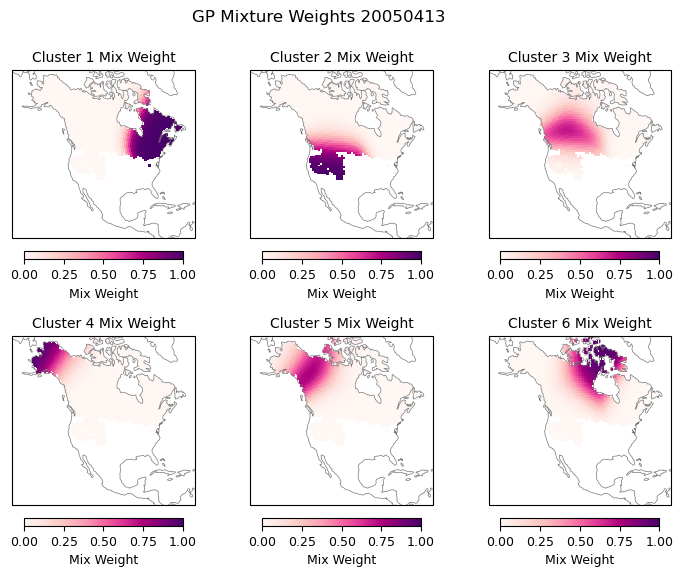

In [19]:

fig = pyplot.figure(figsize=(9,6))
trnsfrm = ccrs.PlateCarree()

for q in range(nclst):
    crwt = mpwtout[q,:,:]
    crwt = ma.masked_where(crwt < -100,crwt)
    pmp = fig.add_subplot(2,3,q+1, projection=ccrs.LambertConformal(central_longitude=-105, central_latitude=33))
    cs = pyplot.pcolormesh(lnarr,ltarr,crwt,vmin=0,vmax=1,transform = trnsfrm,cmap=pyplot.get_cmap('RdPu'))
    pmp.coastlines(color='#777777',linewidth=0.5)
    pmp.set_extent([-140, -70, 10, 75])
    cbar = pyplot.colorbar(cs,extend='neither',orientation='horizontal',shrink=0.8,pad=0.06)
    cbar.set_label('Mix Weight',size=9)
    cbar.ax.tick_params(labelsize=9)
    tstr = 'Cluster %s Mix Weight' % (q+1)
    pyplot.title(tstr,fontsize=10)

fig.subplots_adjust(bottom=0.08,top=0.88,left=0.15,right=0.9, \
                    hspace=0.25,wspace=0.2)
ftstr = 'GP Mixture Weights %s' % (tgtdt)
fig.suptitle(ftstr,fontsize=12)
pyplot.show()

Next, the mixture weighted GP parameters per location are computed

In [20]:
# Assemble weighted parameters
wtsqrrng = numpy.zeros( (nvld,), dtype=numpy.float32)
wtgpvar = numpy.zeros( (nvld,), dtype=numpy.float32)
wtnugget = numpy.zeros( (nvld,), dtype=numpy.float32)

for q in range(nclst):
    wtsqrrng = wtsqrrng + prlstout['Lengthscale'].values[q] * prlstout['Lengthscale'].values[q] * mixwts[q,:]
    wtgpvar = wtgpvar + prlstout['VarScale'].values[q] * mixwts[q,:]
    wtnugget = wtnugget + prlstout['Nugget'].values[q] * mixwts[q,:]


Add a function for computing Matern covariances given a distance matrix

In [21]:
def matern_kernel_from_distance(
    dist_matrix: torch.Tensor, lengthscale: float = 1.0, nu: float = 2.5
) -> torch.Tensor:
  """Computes a Matern covariance matrix directly from a distance matrix."""
  scaled_dist = dist_matrix / lengthscale

  if nu == 0.5:
    return torch.exp(-scaled_dist)
  elif nu == 1.5:
    sqrt3_d = math.sqrt(3.0) * scaled_dist
    return (1.0 + sqrt3_d) * torch.exp(-sqrt3_d)
  elif nu == 2.5:
    sqrt5_d = math.sqrt(5.0) * scaled_dist
    return (1.0 + sqrt5_d + (5.0 / 3.0) * (scaled_dist**2)) * torch.exp(-sqrt5_d)
  else:
    raise ValueError("nu must be one of {0.5, 1.5, 2.5}")



Compute the nonstationary correlation matrix, followed by covariance. The covariance includes the GP process standard deviations and nugget variances.

In [22]:

## Construct the nonstationary covariance, re-normalize with a unit range Matern GP

# Squared distances in Euclidean
urps = numpy.tile(lcsadj[:,0], (nvld,1))
vrps = numpy.tile(lcsadj[:,1], (nvld,1))
udif = urps - numpy.transpose(urps)
vdif = vrps - numpy.transpose(vrps)
dstmtsqr = (udif * udif) + (vdif * vdif)

# Matrix of range parameters
rngrps = numpy.tile(wtsqrrng, (nvld,1))
rangeij = 0.5 * (rngrps + numpy.transpose(rngrps))

# Q_ij "distances"
qdsts = numpy.sqrt(dstmtsqr / rangeij)
qtns = torch.tensor(qdsts)

# Matern evaluation, unit range param
K = matern_kernel_from_distance(qtns, lengthscale=1.0, nu=mtrnnu)

# Re-normalize by Paciorek eq. 7
# det of rangeij is rangeij for isotropic case
nrmcr = numpy.sqrt(rngrps) * numpy.sqrt(numpy.transpose(rngrps)) / rangeij
cornstn = nrmcr * K.numpy()

# Positive definite?
ctrcvsym = 0.5 * (cornstn + numpy.transpose(cornstn)) 
cvvl, cvvc = linalg.eig(ctrcvsym)
print(numpy.amin(cvvl))

# Incorporate variances, nuggets
gpsdrp = numpy.tile( numpy.sqrt(wtgpvar), (nvld,1))

cvmt = gpsdrp * numpy.transpose(gpsdrp) * ctrcvsym + wtnugget * numpy.eye(nvld)

#covar = covar_module(index_pts) 
#cvmt = exp_amplitude * covar.numpy() + nugget * numpy.eye(nrw)

cvvl, cvvc = linalg.eig(cvmt)
print(numpy.amin(cvvl))



0.002526635496532127


0.03246323303041411


In [23]:
rngrps.shape

(1690, 1690)

In [24]:
qdsts[85:88,85:88]

array([[0.        , 0.30781629, 0.61426195],
       [0.30781629, 0.        , 0.3064612 ],
       [0.61426195, 0.3064612 , 0.        ]])

In [25]:
K[85:88,85:88]

tensor([[1.0000, 0.8996, 0.7123],
        [0.8996, 1.0000, 0.9003],
        [0.7123, 0.9003, 1.0000]], dtype=torch.float64)

In [26]:
cvmt[85:88,85:88]

array([[1.27381271, 0.84818555, 0.67156816],
       [0.84818555, 1.27382279, 0.8488722 ],
       [0.67156816, 0.8488722 , 1.27380407]])

In [27]:
rngrps[85:88,85:88]

array([[0.00282863, 0.00282871, 0.00282864],
       [0.00282863, 0.00282871, 0.00282864],
       [0.00282863, 0.00282871, 0.00282864]])

In [28]:
rangeij[85:88,85:88]

array([[0.00282863, 0.00282867, 0.00282864],
       [0.00282867, 0.00282871, 0.00282868],
       [0.00282864, 0.00282868, 0.00282864]])

In [29]:
wtnugget[85:88]

array([0.33093095, 0.33096876, 0.33093326])

In [30]:
print(numpy.amin(wtnugget))

0.02910976722803762


In [31]:
print(numpy.amin(wtgpvar))

0.935042412332144
